# IMDb Sentiment: Logistic Regression

Binary sentiment classification (positive / negative) of 50,000 IMDb movie reviews using Bag-of-Words features and Logistic Regression.

**Data:** `IMDB Dataset.csv` (see [`../data/README.md`](../data/README.md)).

In [13]:
# Step 1: Import the libraries
import pandas as pd
import numpy as np
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

DATA_DIR = "../data/"

In [14]:
# Step 2: Load the dataset (`IMDB Dataset.csv`)
reviews = pd.read_csv(DATA_DIR + 'IMDB Dataset.csv', encoding='latin-1', header=0)

In [15]:
# Show the first rows to understand the structure of the dataset
print("Primeras filas del conjunto de datos:")
reviews.head()

Primeras filas del conjunto de datos:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [16]:
# Step 3: Preprocessing
# Keep only the relevant columns (text and sentiment label)
data = reviews[["review", "sentiment"]].dropna()

In [17]:
# Remove HTML tags from the reviews
def clean_html(text):
    return re.sub(r'<.*?>', '', text)

data["review"] = data["review"].apply(clean_html)

In [18]:
# Convert labels to binary (positive = 1, negative = 0)
data["sentiment"] = data["sentiment"].map({"positive": 1, "negative": 0})

In [19]:
# Check the result
print(data['sentiment'].unique())

[1 0]


In [20]:
# Number of positive and negative reviews
print(data['sentiment'].value_counts())

sentiment
1    25000
0    25000
Name: count, dtype: int64


In [21]:
# Split into input text (X) and labels (y)
X = data["review"]
y = data["sentiment"]

In [22]:
# Step 4: Split into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [23]:
# Step 5: Vectorize the text
# Bag-of-Words representation with CountVectorizer
vectorizer = CountVectorizer(stop_words="english")
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [24]:
# Step 6: Train the model
# Logistic Regression as the baseline model
model = LogisticRegression(max_iter=500)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=500)

In [25]:
# Step 7: Evaluate the model
# Predictions on the test set
y_pred = model.predict(X_test_vec)

In [26]:
# Classification report
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.89      0.88      0.88      4961
           1       0.88      0.89      0.89      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



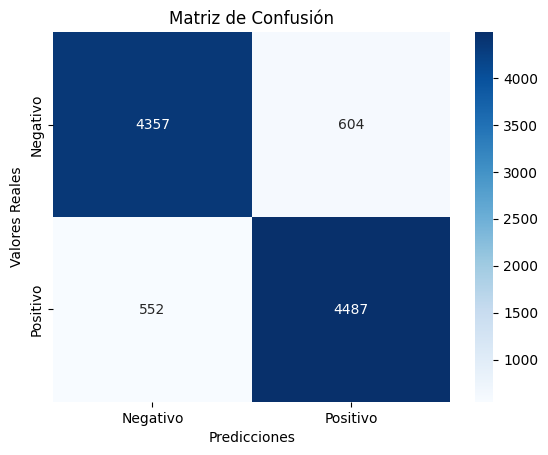

In [27]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negativo', 'Positivo'], yticklabels=['Negativo', 'Positivo'])
plt.xlabel("Predicciones")
plt.ylabel("Valores Reales")
plt.title("Matriz de Confusión")
plt.show()

In [28]:
# Step 8: Overall accuracy
accuracy = np.mean(y_pred == y_test)
print(f"Precisión General del Modelo: {accuracy * 100:.2f}%")

Precisión General del Modelo: 88.44%


## Results

- **Accuracy:** 88.44% on the 10,000 test reviews, a solid result for this task.
- **Precision:** 88% or higher for both classes, so the predictions are balanced.
- **Recall:** 88–89%, the model captures most reviews of each class.
- **F1-score:** 88–89% for both classes, a consistent performance.
- **Confusion matrix:** the model works well on both classes, with a slight tendency to label negative reviews as positive (more false positives than false negatives).

**Conclusion:** with accuracy close to 90%, this simple model is a good baseline for sentiment classification.